# N1 — Nettoyage et imputation de la base d'enquête

## Étape 0 : bibliothèques

> ⚠️ **Données synthétiques** — ce notebook s'exécute sur des données générées par `generate_dummy_data.py`. Les valeurs, proportions et graphiques affichés sont aléatoires et ne décrivent aucune population réelle.

| | Fichiers |
|---|---|
| **Entrée** | `data/1_Donnees_brutes/Immigration.xlsx` |
| **Sortie** | `data/2_Donnees_nettoyees/immigration_nettoyee.xlsx` |

pandas / NumPy pour la manipulation des données, Matplotlib pour les graphiques de contrôle, `KNNImputer` (scikit-learn) pour l'imputation par plus proches voisins.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer

Chargement du fichier Excel brut (`pd.read_excel`).

In [2]:
df = pd.read_excel("../data/1_Donnees_brutes/Immigration.xlsx")

# Étape 1 : exploration de la base

Vue d'ensemble avant nettoyage : dimensions (`shape`), types et nombre de valeurs non nulles par colonne (`info()`).

In [3]:
print("Nombre de lignes de la base : ", df.shape[0], "\nNombre de colonnes de la base : ", df.shape[1], "\n")

df.info()

Nombre de lignes de la base :  5000 
Nombre de colonnes de la base :  21 

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   COUNTRY_ID                    5000 non-null   int64  
 1   Country                       5000 non-null   str    
 2   ID                            5000 non-null   int64  
 3   DATE                          5000 non-null   int64  
 4   Bankaccount                   5000 non-null   int64  
 5   Remit                         5000 non-null   int64  
 6   Regionf                       5000 non-null   int64  
 7   Educationf                    4980 non-null   float64
 8   Genderf                       5000 non-null   int64  
 9   Social statusf                4980 non-null   float64
 10  Age                           4933 non-null   float64
 11  Professional situationf       4984 non-null   float64
 12

Nombre de valeurs manquantes par colonne (`isnull().sum()`).

In [4]:
missing_counts = df.isnull().sum()
print(missing_counts)

COUNTRY_ID                         0
Country                            0
ID                                 0
DATE                               0
Bankaccount                        0
Remit                              0
Regionf                            0
Educationf                        20
Genderf                            0
Social statusf                    20
Age                               67
Professional situationf           16
Corruption (0  1)                701
Corruption                       701
GeneralizedTrsut                2732
TrustCourts                      586
TrustLocalGovernement            868
Trust_Parliament                 901
Trust_Regiol_Governement        3115
intention_to_migrate_legal        32
intention_to_migrate_illegal    3375
dtype: int64


Taux de valeurs manquantes par colonne, en pourcentage. Ce vecteur `missing_percentage` est la base de la stratégie d'imputation : **chaque colonne est orientée vers une méthode selon son taux de manquants** (étapes 3 à 5).

In [5]:
total_rows = len(df)
missing_percentage = (df.isnull().sum() / total_rows) * 100
print(missing_percentage)

COUNTRY_ID                       0.00
Country                          0.00
ID                               0.00
DATE                             0.00
Bankaccount                      0.00
Remit                            0.00
Regionf                          0.00
Educationf                       0.40
Genderf                          0.00
Social statusf                   0.40
Age                              1.34
Professional situationf          0.32
Corruption (0  1)               14.02
Corruption                      14.02
GeneralizedTrsut                54.64
TrustCourts                     11.72
TrustLocalGovernement           17.36
Trust_Parliament                18.02
Trust_Regiol_Governement        62.30
intention_to_migrate_legal       0.64
intention_to_migrate_illegal    67.50
dtype: float64


## Remplacement des chaînes vides par `NaN`

Les cellules vides importées comme chaînes `""` sont converties en `NaN` pour être reconnues comme valeurs manquantes par pandas et scikit-learn. Le travail se fait sur une copie (`df2`) afin de conserver la base brute `df` pour les comparaisons.

In [6]:
df2 = df.copy()
df2.replace("", np.nan, inplace=True)

,COUNTRY_ID,Country,ID,DATE,Bankaccount,Remit,Regionf,Educationf,Genderf,Social statusf,...,Professional situationf,Corruption (0 1),Corruption,GeneralizedTrsut,TrustCourts,TrustLocalGovernement,Trust_Parliament,Trust_Regiol_Governement,intention_to_migrate_legal,intention_to_migrate_illegal
0,1,ALGERIA,10001,44718,0,1,3,3.0,0,1.0,...,4.0,1.0,1.0,NaN,0.0,0.0,NaN,NaN,0.0,NaN
1,1,ALGERIA,10002,44513,0,1,1,5.0,1,3.0,...,4.0,0.0,4.0,1.0,1.0,0.0,1.0,NaN,1.0,NaN
2,1,ALGERIA,10003,44479,1,1,2,6.0,0,1.0,...,4.0,1.0,2.0,NaN,0.0,1.0,1.0,NaN,0.0,NaN
3,1,ALGERIA,10004,44757,0,0,3,1.0,1,1.0,...,4.0,0.0,3.0,NaN,0.0,1.0,0.0,0.0,0.0,NaN
4,1,ALGERIA,10005,44576,0,1,2,7.0,0,1.0,...,NaN,0.0,3.0,1.0,1.0,0.0,1.0,1.0,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,21,TUNISIA,210411,44605,0,1,3,7.0,1,7.0,...,7.0,0.0,4.0,NaN,0.0,0.0,1.0,1.0,1.0,NaN
4996,21,TUNISIA,210412,44603,0,0,3,1.0,1,6.0,...,6.0,NaN,NaN,NaN,1.0,0.0,1.0,NaN,0.0,NaN
4997,21,TUNISIA,210413,44533,1,1,1,3.0,1,5.0,...,4.0,1.0,1.0,NaN,1.0,1.0,1.0,NaN,1.0,0.0
4998,21,TUNISIA,210414,44570,0,1,3,7.0,1,6.0,...,3.0,1.0,1.0,NaN,0.0,1.0,1.0,NaN,0.0,NaN


## Typage des variables

Les variables qualitatives sont codées numériquement : elles sont converties en type `category` pour que pandas ne les traite pas comme des grandeurs continues. `Age` reste numérique (la conversion en `int` est impossible tant que la colonne contient des `NaN`). Le `print(df2.columns)` préalable permet de repérer les noms de colonnes contenant des espaces parasites.

In [7]:
# Pour voir le bon libéllé des colones et trouvé les espaces caché
print(df2.columns)
df2["Educationf"] = df2["Educationf"].astype("category")
df2["Bankaccount"] = df2["Bankaccount"].astype("category")
df2["Remit"] = df2["Remit"].astype("category")
df2["Regionf"] = df2["Regionf"].astype("category")
df2["Educationf"] = df2["Educationf"].astype("category")
df2["Genderf"] = df2["Genderf"].astype("category")
df2["Social statusf"] = df2["Social statusf"].astype("category")
# PROBLEME car valeur vide on se permet de le laisser comme ceci
# df2["Age"] = df2["Age"].astype("int")
df2["Corruption (0  1)"] = df2["Corruption (0  1)"].astype("category")
df2["Corruption "] = df2["Corruption "].astype("category")
df2["GeneralizedTrsut"] = df2["GeneralizedTrsut"].astype("category")
df2["TrustCourts"] = df2["TrustCourts"].astype("category")
df2["TrustLocalGovernement"] = df2["TrustLocalGovernement"].astype("category")
df2["Trust_Parliament"] = df2["Trust_Parliament"].astype("category")
df2["Trust_Regiol_Governement "] = df2["Trust_Regiol_Governement "].astype("category")
df2["intention_to_migrate_legal"] = df2["intention_to_migrate_legal"].astype("category")
df2["intention_to_migrate_illegal"] = df2["intention_to_migrate_illegal"].astype("category")
df2["Professional situationf"] = df2["Professional situationf"].astype("category")
df2.info()

Index(['COUNTRY_ID', 'Country', 'ID', 'DATE', 'Bankaccount', 'Remit',
       'Regionf', 'Educationf', 'Genderf', 'Social statusf', 'Age',
       'Professional situationf', 'Corruption (0  1)', 'Corruption ',
       'GeneralizedTrsut', 'TrustCourts', 'TrustLocalGovernement',
       'Trust_Parliament', 'Trust_Regiol_Governement ',
       'intention_to_migrate_legal', 'intention_to_migrate_illegal'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   COUNTRY_ID                    5000 non-null   int64   
 1   Country                       5000 non-null   str     
 2   ID                            5000 non-null   int64   
 3   DATE                          5000 non-null   int64   
 4   Bankaccount                   5000 non-null   category
 5   Remit                         5000 non-null   category
 6  

# Étape 2 : nettoyage

## Contrôle des doublons

Les doublons sont contrôlés sur l'identifiant `ID` uniquement. La suppression des doublons sur l'ensemble des colonnes (`drop_duplicates()`) est volontairement désactivée : la base ne contenant que des variables codées à peu de modalités, deux répondants distincts peuvent légitimement présenter exactement le même profil.

In [8]:
nb_doublons_id = df["ID"].duplicated().sum()
print(nb_doublons_id)
# df2 = df2.drop_duplicates()

# print("Nombre de lignes de la base originale : ", df.shape[0], "\n")
# print("Nombre de lignes de la base modifiée : ", df2.shape[0], "\n")

0


## Normalisation des noms de colonnes

Suppression des espaces parasites en fin de nom (`'Corruption '`, `'Trust_Regiol_Governement '`) via `rename`, pour fiabiliser l'accès aux colonnes dans la suite du pipeline.

In [9]:
df2 = df2.rename(columns={'Corruption ': 'Corruption', 'Trust_Regiol_Governement ': 'Trust_Regiol_Governement'})
print(df2.columns)

Index(['COUNTRY_ID', 'Country', 'ID', 'DATE', 'Bankaccount', 'Remit',
       'Regionf', 'Educationf', 'Genderf', 'Social statusf', 'Age',
       'Professional situationf', 'Corruption (0  1)', 'Corruption',
       'GeneralizedTrsut', 'TrustCourts', 'TrustLocalGovernement',
       'Trust_Parliament', 'Trust_Regiol_Governement',
       'intention_to_migrate_legal', 'intention_to_migrate_illegal'],
      dtype='str')


# Étape 3 : imputation des colonnes à moins de 2 % de manquants

Imputation **simple par le mode** pour les variables qualitatives faiblement incomplètes : avec moins de 2 % de valeurs remplacées, l'effet sur les distributions est négligeable et une méthode plus coûteuse ne se justifie pas. Le bloc filtre `missing_percentage` sur l'intervalle ]0 ; 2[ pour contrôle, applique `fillna(mode()[0])` à la liste de colonnes retenue, puis vérifie le taux de manquants résiduel.

In [10]:
moins2_percentage = missing_percentage[(missing_percentage > 0) & (missing_percentage < 2)]
print(moins2_percentage)

# Les colonnes qualitatif qu'on souhaite garder pour appliquer la méthode mode, on appliquera la méthode médiane à Age
colonne_mode = ["Educationf","Social statusf","Professional situationf","intention_to_migrate_legal"]

for column in colonne_mode:
    df2[column] = df2[column].fillna(df2[column].mode()[0])

total_rows = len(df2)
missing_percentage = (df2.isnull().sum() / total_rows) * 100
print("\nAffichage des valeurs de nos colonnes après applications :")
test = missing_percentage[colonne_mode]
print(test)

Educationf                    0.40
Social statusf                0.40
Age                           1.34
Professional situationf       0.32
intention_to_migrate_legal    0.64
dtype: float64

Affichage des valeurs de nos colonnes après applications :
Educationf                    0.0
Social statusf                0.0
Professional situationf       0.0
intention_to_migrate_legal    0.0
dtype: float64


`Age` étant quantitative, elle est imputée par la **médiane** plutôt que par le mode : la médiane est robuste aux valeurs extrêmes et adaptée à une distribution asymétrique.

In [11]:
df2["Age"] = df2["Age"].fillna(df2["Age"].median())

missing_percentage = (df2.isnull().sum() / total_rows) * 100
print("Affichage de la colonne Age après application de la médiane sur les valeurs manquantes :")
print(missing_percentage["Age"])
print(missing_percentage)

Affichage de la colonne Age après application de la médiane sur les valeurs manquantes :
0.0
COUNTRY_ID                       0.00
Country                          0.00
ID                               0.00
DATE                             0.00
Bankaccount                      0.00
Remit                            0.00
Regionf                          0.00
Educationf                       0.00
Genderf                          0.00
Social statusf                   0.00
Age                              0.00
Professional situationf          0.00
Corruption (0  1)               14.02
Corruption                      14.02
GeneralizedTrsut                54.64
TrustCourts                     11.72
TrustLocalGovernement           17.36
Trust_Parliament                18.02
Trust_Regiol_Governement        62.30
intention_to_migrate_legal       0.00
intention_to_migrate_illegal    67.50
dtype: float64


# Étape 4 : imputation KNN des colonnes à 10-20 % de manquants

## Préparation : copie de travail dédiée

### Principe

`KNNImputer` estime chaque valeur manquante à partir des *k* observations les plus proches, la distance étant calculée sur les variables renseignées (`nan_euclidean`). La méthode exploite les corrélations entre variables : des répondants au profil proche (âge, éducation, situation professionnelle, pays) ont des réponses proches.

Avant l'imputation, on retire de la copie de travail :

- `Country`, colonne texte incompatible avec un calcul de distance (le pays reste représenté par son code `COUNTRY_ID`) ;
- les trois colonnes à plus de 50 % de manquants, traitées à l'étape 5, pour qu'elles ne dégradent pas le calcul des distances.

In [12]:
df_pour_knn = df2.copy()
df_pour_knn = df_pour_knn.drop(columns=["Country","GeneralizedTrsut","Trust_Regiol_Governement","intention_to_migrate_illegal"])

In [13]:
imputer = KNNImputer(n_neighbors=11, weights="distance")
test_imputer = imputer.fit_transform(df_pour_knn)

df_final = pd.DataFrame(test_imputer, columns=df_pour_knn.columns)
df_final = df_final.round().astype(int)

colonnes_knn = ["TrustCourts", "TrustLocalGovernement", "Trust_Parliament",
                "Corruption", "Corruption (0  1)"]

for col in colonnes_knn:
    if col in df_final.columns:
        df2[col] = df_final[col].round().astype("int").values

df_final.head()

,COUNTRY_ID,ID,DATE,Bankaccount,Remit,Regionf,Educationf,Genderf,Social statusf,Age,Professional situationf,Corruption (0 1),Corruption,TrustCourts,TrustLocalGovernement,Trust_Parliament,intention_to_migrate_legal
0,1,10001,44718,0,1,3,3,0,1,51,4,1,1,0,0,1,0
1,1,10002,44513,0,1,1,5,1,3,31,4,0,4,1,0,1,1
2,1,10003,44479,1,1,2,6,0,1,52,4,1,2,0,1,1,0
3,1,10004,44757,0,0,3,1,1,1,48,4,0,3,0,1,0,0
4,1,10005,44576,0,1,2,7,0,1,38,4,0,3,1,0,1,1


### Paramétrage

- `n_neighbors=11` : un voisinage large lisse l'influence d'observations atypiques ;
- `weights="distance"` : les voisins les plus proches pèsent davantage dans l'estimation, ce qui justifie en contrepartie un *k* élevé ;
- *k* impair : limite les situations d'égalité sur les variables binaires.

Le KNN produisant des moyennes pondérées (valeurs réelles), les résultats sont arrondis (`round().astype(int)`) pour retrouver des codes de modalité valides. Seules les colonnes ciblées (`colonnes_knn`) sont réinjectées dans `df2`.

### Contrôle post-imputation

In [14]:
print("df2 après KNN :")
print(f"(lignes, colonnes): {df2.shape}")
print(f"\nManquants par colonne (en %) :")
manquants_pct = (df2.isna().sum() / len(df2) * 100).round(2)
print(manquants_pct.sort_values(ascending=False))

df2 après KNN :
(lignes, colonnes): (5000, 21)

Manquants par colonne (en %) :
intention_to_migrate_illegal    67.50
Trust_Regiol_Governement        62.30
GeneralizedTrsut                54.64
Country                          0.00
COUNTRY_ID                       0.00
Bankaccount                      0.00
DATE                             0.00
ID                               0.00
Remit                            0.00
Social statusf                   0.00
Regionf                          0.00
Educationf                       0.00
Genderf                          0.00
Corruption (0  1)                0.00
Professional situationf          0.00
Age                              0.00
Corruption                       0.00
TrustLocalGovernement            0.00
TrustCourts                      0.00
Trust_Parliament                 0.00
intention_to_migrate_legal       0.00
dtype: float64


Le taux de manquants doit être nul pour toutes les colonnes imputées ; seules les colonnes réservées à l'étape 5 restent incomplètes.

# Étape 5 : imputation des colonnes à 50 % de manquants ou plus

Imputation **itérative** (`IterativeImputer`, approche de type MICE) avec un `RandomForestRegressor` comme estimateur : chaque colonne incomplète est modélisée tour à tour en fonction des autres, et l'opération est répétée jusqu'à convergence.

- `Country` est encodé en variables indicatrices (`get_dummies`, `drop_first=True` pour éviter la colinéarité parfaite) ; seules les colonnes numériques et booléennes sont conservées ;
- forêt de 100 arbres, profondeur maximale 10 (limite le surapprentissage), `n_jobs=-1` pour paralléliser ;
- initialisation par la médiane, `max_iter=10`, `random_state=42` pour la reproductibilité.

Les prédictions sont arrondies puis réinjectées dans `df2` ; le bloc se termine par un contrôle des manquants restants et de la distribution des valeurs imputées.

In [15]:
# convertir les 3 colonnes en numérique

for col in ["GeneralizedTrsut", "Trust_Regiol_Governement", "intention_to_migrate_illegal"]:
    df2[col] = pd.to_numeric(df2[col], errors="coerce")

# Vérification
print("Types après conversion :")
for col in ["GeneralizedTrsut", "Trust_Regiol_Governement", "intention_to_migrate_illegal"]:
    nb_na = df2[col].isna().sum()
    dtype = df2[col].dtype
    print(f"  '{col}' : type = {dtype}, manquants = {nb_na}")

from sklearn.experimental import enable_iterative_imputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import IterativeImputer

# Étape 1 : Préparer les données
df_pour_rf = df2.copy()
df_pour_rf = pd.get_dummies(df_pour_rf, columns=["Country"], prefix="C", drop_first=True)
df_pour_rf = df_pour_rf.select_dtypes(include=["number", "bool"])

print(f"(lignes x colonnes) : {df_pour_rf.shape}")
print(f"Manquants à imputer : {df_pour_rf.isna().sum().sum()}\n")

# Étape 2 : Configurer le modèle Random Forest
modele_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    n_jobs=-1,
    random_state=42
)

imputer_rf = IterativeImputer(
    estimator=modele_rf,
    max_iter=10,
    initial_strategy="median",
    random_state=42,
    verbose=2
)

# Étape 3 : Lancer l'imputation
df_rf_imputed = pd.DataFrame(imputer_rf.fit_transform(df_pour_rf), columns=df_pour_rf.columns,index=df_pour_rf.index)

# Étape 4 : Récupérer les 3 colonnes dans df2
colonnes_rf = ["GeneralizedTrsut", "Trust_Regiol_Governement", "intention_to_migrate_illegal"]

for col in colonnes_rf:
    if col in df_rf_imputed.columns:
        df2[col] = df_rf_imputed[col].round().astype("int").values
        print(f"  ✓ '{col}' imputée et récupérée dans df2")

# Étape 5 : Vérification finale
print("Vérification :")

manquants = df2.isna().sum()
manquants = manquants[manquants > 0]

if len(manquants) == 0:
    print("\nLa base est nettoyée.")
else:
    print(f"\nManquants restants :")
    print(manquants)

print(f"\nDimensions finales : {df2.shape[0]} lignes × {df2.shape[1]} colonnes")

# Distribution des valeurs imputées
print("\nDistribution des valeurs imputées :")
for col in colonnes_rf:
    print(f"\n{col}")
    print(df2[col].value_counts(normalize=True).round(3) * 100)

Types après conversion :
  'GeneralizedTrsut' : type = float64, manquants = 2732
  'Trust_Regiol_Governement' : type = float64, manquants = 3115
  'intention_to_migrate_illegal' : type = float64, manquants = 3375


(lignes x colonnes) : (5000, 22)
Manquants à imputer : 9222

[IterativeImputer] Completing matrix with shape (5000, 22)


[IterativeImputer] Ending imputation round 1/10, elapsed time 3.66
[IterativeImputer] Change: 1.6719935029170254, scaled tolerance: 210.415 
[IterativeImputer] Early stopping criterion reached.
  ✓ 'GeneralizedTrsut' imputée et récupérée dans df2
  ✓ 'Trust_Regiol_Governement' imputée et récupérée dans df2
  ✓ 'intention_to_migrate_illegal' imputée et récupérée dans df2
Vérification :

La base est nettoyée.

Dimensions finales : 5000 lignes × 21 colonnes

Distribution des valeurs imputées :

GeneralizedTrsut
GeneralizedTrsut
1    60.5
0    39.5
Name: proportion, dtype: float64

Trust_Regiol_Governement
Trust_Regiol_Governement
0    81.0
1    19.0
Name: proportion, dtype: float64

intention_to_migrate_illegal
intention_to_migrate_illegal
0    82.7
1    17.3
Name: proportion, dtype: float64


## Note sur la convergence et la distribution des valeurs imputées

`IterativeImputer` peut s'arrêter avant `max_iter` : dès que la variation entre deux itérations passe sous la tolérance (`tol`), le critère d'arrêt anticipé est déclenché, ce qui apparaît dans les logs (`verbose=2`).

L'affichage de la distribution des valeurs imputées (`value_counts(normalize=True)`) sert de garde-fou : un modèle entraîné sur des classes déséquilibrées a tendance à reproduire, voire amplifier, la surreprésentation de la classe majoritaire. Plus le taux de manquants initial est élevé, moins l'imputation est fiable.

## Évaluation de l'imputation par masquage

Principe : on masque aléatoirement 20 % des valeurs connues d'une colonne (`np.random.choice`, graine fixée), on relance l'imputation, puis on compare les valeurs reprédites aux valeurs masquées. La métrique est l'*accuracy* (`accuracy_score`) : la part de valeurs correctement retrouvées.

Limite assumée : le test est effectué sur `df2`, qui contient déjà les valeurs imputées à l'étape précédente. Le score est donc un ordre de grandeur et non une évaluation strictement indépendante.

In [16]:
from sklearn.metrics import accuracy_score

# Préparer la base depuis df2
df_prep = df2.copy()
df_prep = pd.get_dummies(df_prep, columns=["Country"], prefix="C", drop_first=True)
df_prep = df_prep.select_dtypes(include=["number", "bool"])

# Stocker les résultats pour la 2e cellule
resultats = {}

# Tester chaque colonne
for col_test in ["GeneralizedTrsut", "Trust_Regiol_Governement", "intention_to_migrate_illegal"]:
    df_test = df_prep.copy()

    # Cacher 20% des valeurs au hasard
    np.random.seed(42)
    n_a_cacher = int(len(df_test) * 0.2)
    indices_a_cacher = np.random.choice(df_test.index, size=n_a_cacher, replace=False)

    vraies_valeurs = df_test.loc[indices_a_cacher, col_test].copy()
    df_test.loc[indices_a_cacher, col_test] = np.nan

    # Imputer
    modele = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
    imputer = IterativeImputer(estimator=modele, max_iter=5, random_state=42, verbose=0)
    df_test_imputed = pd.DataFrame(imputer.fit_transform(df_test), columns=df_test.columns, index=df_test.index)

    # Comparer
    valeurs_predites = df_test_imputed.loc[indices_a_cacher, col_test].round().astype(int)
    vraies = vraies_valeurs.astype(int)
    precision = accuracy_score(vraies, valeurs_predites)

    resultats[col_test] = {"vraies": vraies.values, "predites": valeurs_predites.values, "precision": precision}

    print(f"{col_test} : précision = {precision:.1%}")

GeneralizedTrsut : précision = 76.2%


Trust_Regiol_Governement : précision = 82.5%


intention_to_migrate_illegal : précision = 81.7%


## Lecture des scores

L'accuracy doit être comparée à une **baseline** : la fréquence de la classe majoritaire. Sur des variables binaires déséquilibrées, un modèle qui prédirait systématiquement la classe majoritaire obtiendrait déjà un score élevé ; seule la marge au-dessus de cette baseline mesure l'apport réel du modèle. On s'attend aussi à ce que le score baisse quand le taux de manquants initial augmente, le modèle disposant de moins d'exemples d'apprentissage.

## Visualisation : valeurs réelles vs valeurs prédites

Pour chaque colonne évaluée, un nuage de points croise les vraies valeurs (axe X) et les valeurs prédites (axe Y) ; la diagonale en pointillés correspond aux prédictions correctes. Les variables étant binaires, tous les points tomberaient sur quatre positions : un léger bruit aléatoire (*jitter*, `np.random.uniform(-0.1, 0.1)`) est ajouté pour rendre la densité lisible.

- (0, 0) et (1, 1) : prédictions correctes ;
- (0, 1) : faux positif ;
- (1, 0) : faux négatif.

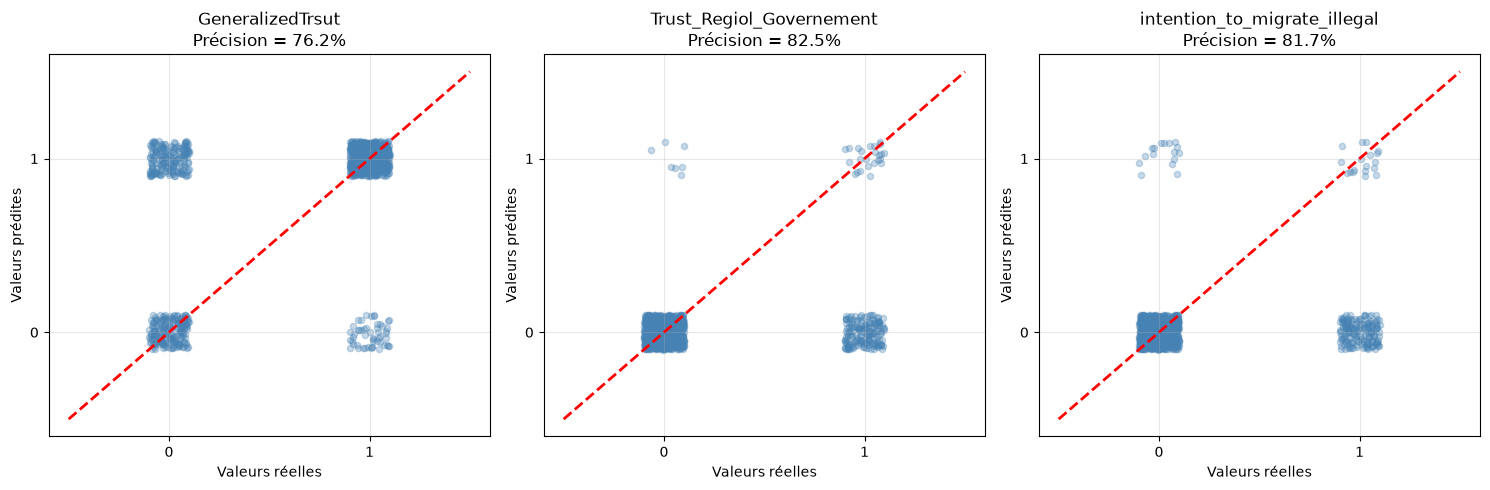

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (col, res) in enumerate(resultats.items()):
    ax = axes[i]

    # Jitter pour voir les points superposés
    np.random.seed(42)
    jitter_x = np.random.uniform(-0.1, 0.1, size=len(res["vraies"]))
    jitter_y = np.random.uniform(-0.1, 0.1, size=len(res["predites"]))

    ax.scatter(res["vraies"] + jitter_x, res["predites"] + jitter_y, alpha=0.3, s=20, color="steelblue")
    ax.plot([-0.5, 1.5], [-0.5, 1.5], "r--", linewidth=2)

    ax.set_xlabel("Valeurs réelles")
    ax.set_ylabel("Valeurs prédites")
    ax.set_title(f"{col}\nPrécision = {res['precision']:.1%}")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Lecture des nuages de points

Comparer la densité des deux quadrants d'erreur permet de diagnostiquer un biais : des faux négatifs plus nombreux que les faux positifs signalent un modèle qui se replie sur la classe majoritaire en cas d'incertitude. Ce diagnostic complète l'accuracy, qui ne distingue pas les deux types d'erreur.

# Étape 6 : export

La base nettoyée et complète est exportée au format `.xlsx` ; elle alimente les notebooks N0 (analyse descriptive) et N4 (fusion).

In [18]:
df2.to_excel("../data/2_Donnees_nettoyees/immigration_nettoyee.xlsx", index=False)
print(f"Base exportée : immigration_nettoyee.xlsx")
print(f"Dimensions : {df2.shape[0]} lignes × {df2.shape[1]} colonnes")
print(f"Manquants restants : {df2.isna().sum().sum()}")

Base exportée : immigration_nettoyee.xlsx
Dimensions : 5000 lignes × 21 colonnes
Manquants restants : 0
